# TP — Seuillage d’images et prédiction du seuil par Machine Learning

**Correction complète et application aux images de `./dataset`.**

Ce notebook suit les parties A à D de l’énoncé : génération reproductible, Otsu, régression linéaire, forêt aléatoire, métriques, visualisations et réponses. Une seconde expérience utilise les photographies locales.

**Distinction essentielle :** les images synthétiques possèdent un seuil cible défini par construction. Pour les photographies, aucun seuil de référence n’est fourni : on étudie une **pseudo-cible**, estimée par regroupement des intensités. Les résultats réels mesurent l’imitation de cette règle et ne prouvent pas une qualité de segmentation.

Exécuter les cellules dans l’ordre avec le noyau Python de **Conda `myenv`**. Dépendances : numpy, opencv, matplotlib, pandas, scikit-learn. Les tableaux seront sauvegardés dans `resultats_seuillage/`.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
OUT = Path('resultats_seuillage')
OUT.mkdir(exist_ok=True)
print('Python :', sys.executable)
print('OpenCV :', cv2.__version__)


Python : /home/amine/anaconda3/envs/myenv/bin/python
OpenCV : 4.13.0


## A — Générer les images et construire les données

Nous générons 240 images de 128 × 128 pixels. Le fond est sombre et l’objet clair ; les intensités, positions, tailles et formes varient. Un bruit gaussien faible est ajouté.

Le seuil cible est le milieu des deux intensités **avant bruit** :

$$T^* = (I_{fond}+I_{objet})/2.$$

Les entrées contiennent la moyenne, l’écart-type et la proportion de pixels ≤ 127. Nous conservons Otsu dans le tableau pour la comparaison, sans l’utiliser comme entrée du modèle : cette décision permet une comparaison avec une prédiction ne calculant pas déjà Otsu.

240 images : 180 apprentissage, 60 test


,moyenne,ecart_type,proportion_le_127,otsu,cible,fond,objet
0,43.138062,58.853140,0.880310,34.0,112.5,22,203
1,114.127747,23.050100,0.824158,115.0,134.0,104,164
2,71.640808,14.115917,0.999939,83.0,93.0,68,118
3,33.818359,34.812102,1.000000,27.0,58.0,16,100
4,77.052490,9.845433,0.973633,87.0,105.0,76,134


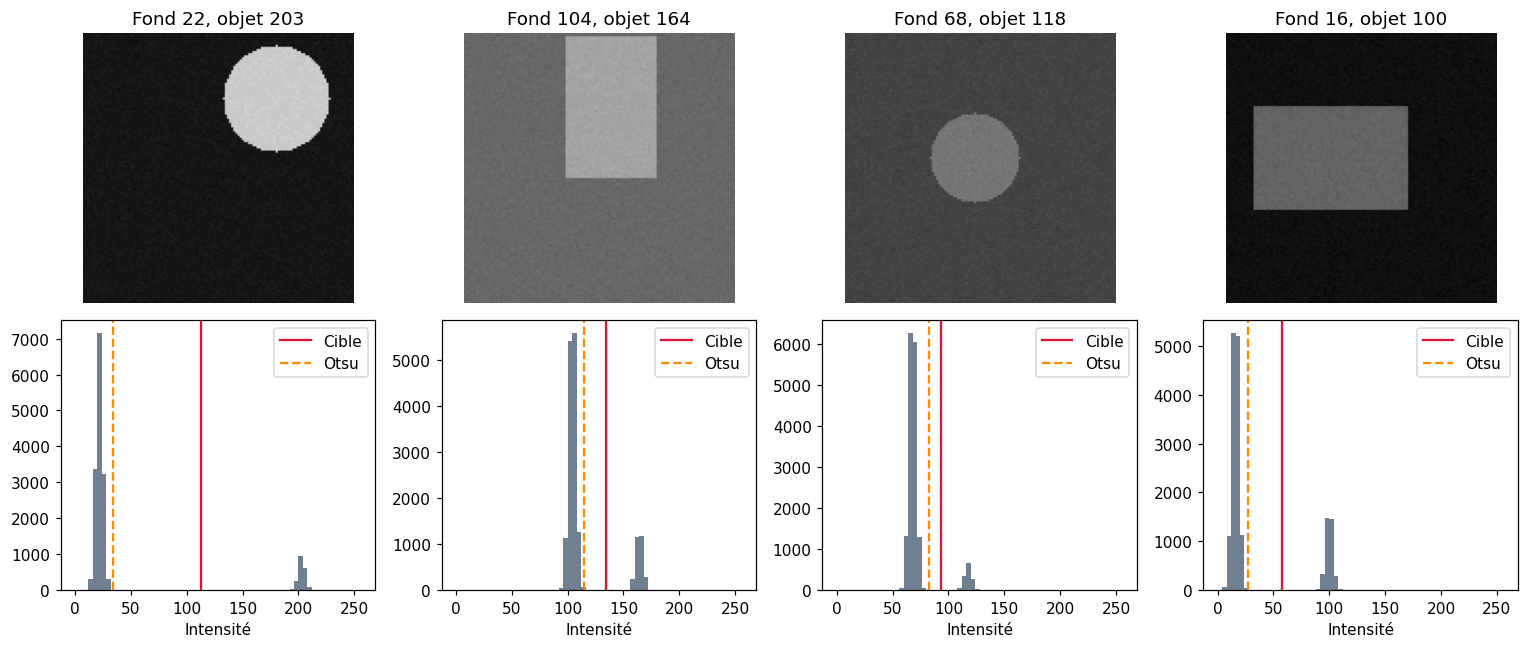

In [2]:
def otsu_threshold(image):
    threshold, binary = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return float(threshold), binary

FEATURES = ['moyenne', 'ecart_type', 'proportion_le_127']
def features(image):
    return [float(image.mean()), float(image.std()), float((image <= 127).mean())]

def generate_image(rng, size=128):
    background = int(rng.integers(10, 145))
    foreground = int(rng.integers(background + 35, 246))
    mask = np.zeros((size, size), dtype=np.uint8)
    if rng.random() < 0.5:
        radius = int(rng.integers(12, 43))
        center = tuple(int(x) for x in rng.integers(radius, size-radius, size=2))
        cv2.circle(mask, center, radius, 1, -1)
    else:
        width, height = rng.integers(25, 95, size=2)
        x = int(rng.integers(0, size-width))
        y = int(rng.integers(0, size-height))
        cv2.rectangle(mask, (x, y), (x+int(width), y+int(height)), 1, -1)
    clean = np.where(mask, foreground, background).astype(float)
    noisy = np.clip(clean + rng.normal(0, 3, clean.shape), 0, 255).astype(np.uint8)
    return noisy, mask.astype(bool), (background+foreground)/2, background, foreground

synthetic = [generate_image(rng) for _ in range(240)]
images_syn = [s[0] for s in synthetic]
masks_syn = [s[1] for s in synthetic]
df_syn = pd.DataFrame([features(im) for im in images_syn], columns=FEATURES)
df_syn['otsu'] = [otsu_threshold(im)[0] for im in images_syn]
df_syn['cible'] = [s[2] for s in synthetic]
df_syn['fond'] = [s[3] for s in synthetic]
df_syn['objet'] = [s[4] for s in synthetic]
train_syn, test_syn = train_test_split(np.arange(len(synthetic)), test_size=0.25, random_state=SEED)
print(f'{len(synthetic)} images : {len(train_syn)} apprentissage, {len(test_syn)} test')
display(df_syn.head())
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for j in range(4):
    axes[0,j].imshow(images_syn[j], cmap='gray', vmin=0, vmax=255)
    axes[0,j].set_title(f'Fond {synthetic[j][3]}, objet {synthetic[j][4]}')
    axes[0,j].axis('off')
    axes[1,j].hist(images_syn[j].ravel(), bins=64, range=(0,256), color='slategray')
    axes[1,j].axvline(df_syn.loc[j,'cible'], color='crimson', label='Cible')
    axes[1,j].axvline(df_syn.loc[j,'otsu'], color='darkorange', linestyle='--', label='Otsu')
    axes[1,j].set_xlabel('Intensité'); axes[1,j].legend()
plt.tight_layout(); plt.show()


### Réponses A

1. Plusieurs images permettent d’apprendre les variations entre exemples et de mesurer la généralisation sur des images non utilisées pour l’entraînement. Une seule image ne suffit pas pour cette évaluation.
2. Une caractéristique est une mesure disponible à l’entrée, par exemple la moyenne. La cible est la valeur à prédire, ici le seuil défini par les intensités connues.
3. Les formes simples, deux intensités et le faible bruit ne reproduisent ni textures complexes, ni éclairage variable, ni occlusions, ni diversité sémantique des photographies.

## B — Calculer et visualiser Otsu

Otsu recherche le seuil maximisant la variance entre deux classes d’intensités. Un seuil optimisant ce critère peut différer du milieu des intensités utilisées pour créer l’image.

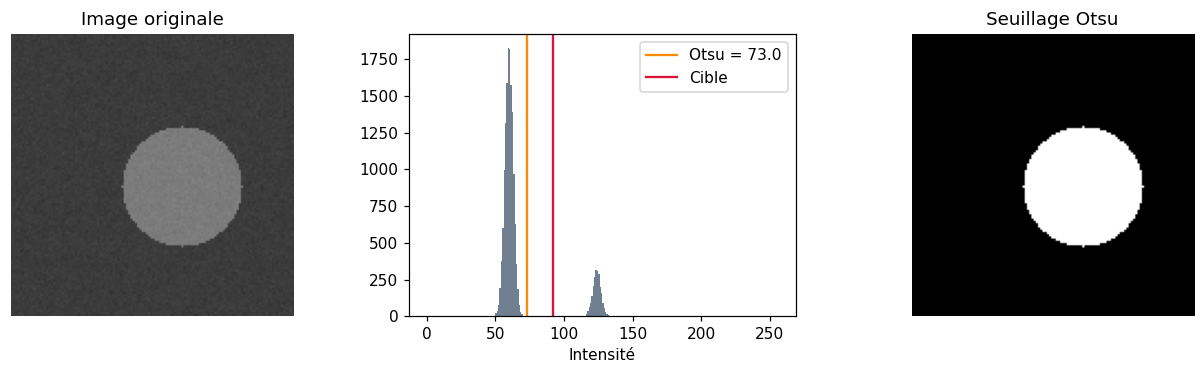

In [3]:
example_idx = int(test_syn[0])
im = images_syn[example_idx]
t, binary = otsu_threshold(im)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(im, cmap='gray', vmin=0, vmax=255); axes[0].set_title('Image originale'); axes[0].axis('off')
axes[1].hist(im.ravel(), bins=256, range=(0,256), color='slategray')
axes[1].axvline(t, color='darkorange', label=f'Otsu = {t:.1f}')
axes[1].axvline(df_syn.loc[example_idx,'cible'], color='crimson', label='Cible')
axes[1].set_xlabel('Intensité'); axes[1].legend()
axes[2].imshow(binary, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Seuillage Otsu'); axes[2].axis('off')
plt.tight_layout(); plt.show()


### Réponses B

1. Avec `THRESH_OTSU`, OpenCV calcule le seuil automatiquement ; la valeur initiale 0 est ignorée.
2. Non. Otsu optimise la séparation statistique de l’histogramme, alors que notre cible est le milieu des intensités nominales. Sur deux pics séparés, plusieurs seuils peuvent produire exactement le même masque.
3. Ombres, illumination non uniforme, faible contraste, bruit et distributions d’intensités qui se recouvrent peuvent rendre un seuil global insuffisant.

## C — Entraîner et évaluer les modèles

Les modèles sont entraînés uniquement sur l’ensemble d’apprentissage. Les métriques ci-dessous portent sur les prédictions brutes ; une version bornée dans [0,255] est utilisée pour les masques binaires. La racine de MSE donne la RMSE.

,MAE,RMSE,R2,"hors_[0,255]"
méthode,,,,
Otsu,40.7667,46.6224,-0.5748,0
Régression linéaire,15.0752,18.0954,0.7628,0
Random Forest,9.1332,11.7762,0.8995,0


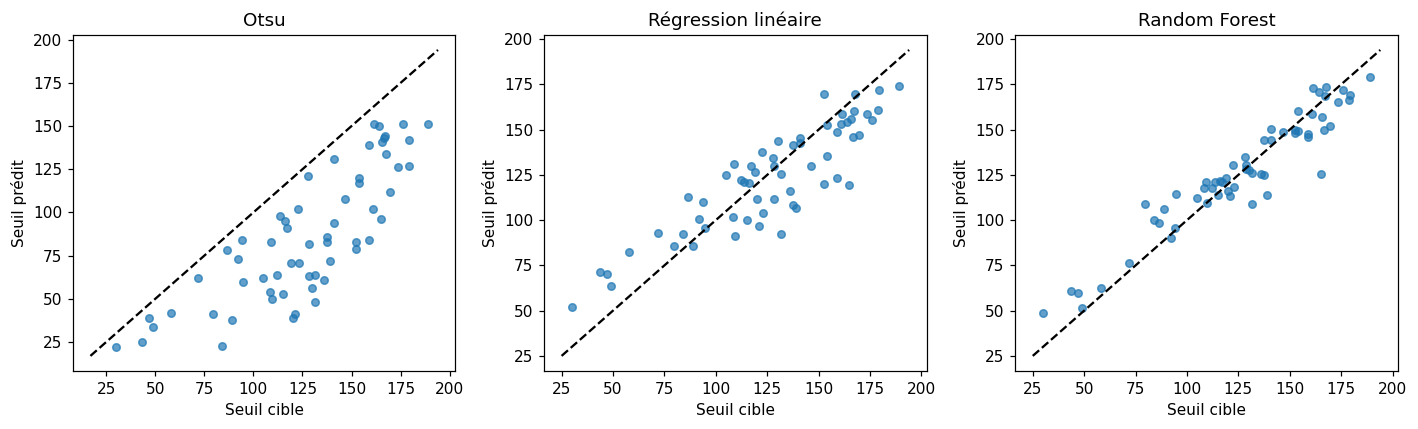

**Réponse C1.** Sur ce test, **Random Forest** obtient la plus petite MAE parmi les deux modèles supervisés (9.133).

In [4]:
def train_evaluate(frame, train_idx, test_idx, label):
    X = frame[FEATURES].to_numpy()
    y = frame['cible'].to_numpy()
    models = {
        'Régression linéaire': LinearRegression(),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    }
    predictions = {'Otsu': frame.iloc[test_idx]['otsu'].to_numpy()}
    for name, model in models.items():
        model.fit(X[train_idx], y[train_idx])
        predictions[name] = model.predict(X[test_idx])
    rows = []
    for name, pred in predictions.items():
        rows.append({'méthode':name, 'MAE':mean_absolute_error(y[test_idx],pred),
                     'RMSE':np.sqrt(mean_squared_error(y[test_idx],pred)),
                     'R2':r2_score(y[test_idx],pred),
                     'hors_[0,255]':int(((pred<0)|(pred>255)).sum())})
    metrics = pd.DataFrame(rows).set_index('méthode')
    display(metrics.round(4))
    metrics.to_csv(OUT / f'{label}_performances.csv')
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, (name, pred) in zip(axes, predictions.items()):
        ax.scatter(y[test_idx], pred, alpha=0.7, s=24)
        low = min(y[test_idx].min(), pred.min())-5
        high = max(y[test_idx].max(), pred.max())+5
        ax.plot([low,high],[low,high], '--', color='black')
        ax.set(xlabel='Seuil cible', ylabel='Seuil prédit', title=name)
    plt.tight_layout(); plt.show()
    return models, predictions, metrics

models_syn, pred_syn, metrics_syn = train_evaluate(df_syn, train_syn, test_syn, 'synthetique')
best_syn = metrics_syn.loc[['Régression linéaire','Random Forest'],'MAE'].idxmin()
display(Markdown(f'**Réponse C1.** Sur ce test, **{best_syn}** obtient la plus petite MAE parmi les deux modèles supervisés ({metrics_syn.loc[best_syn,"MAE"]:.3f}).'))


### Réponses C2–C3

2. Le test estime les erreurs sur des exemples que le modèle n’a pas vus. Évaluer sur l’apprentissage donnerait une estimation trop optimiste, en particulier pour un modèle flexible.
3. Non : la performance dépend de la distribution des images, des caractéristiques et de la définition de la cible. Une bonne MAE synthétique ne démontre pas un avantage sur des photographies.

## D — Comparaison sur les mêmes images de test

Trois exemples de test sont choisis avant examen de leurs erreurs. Pour chaque image, nous affichons l’original et les quatre masques (cible, Otsu, régression, forêt). Le masque de l’objet synthétique fournit également une référence de segmentation indépendante : nous calculons l’IoU et l’exactitude des pixels.

L’IoU est l’intersection divisée par l’union entre pixels prédits comme objet et pixels appartenant réellement à l’objet.

,image_index,méthode,seuil_brut,seuil_appliqué,cible,erreur_absolue,pixels_différents_cible_pct,IoU_objet,exactitude_pixels,commentaire
0,24,Cible,92.0000,92.0000,92.0,0.0000,0.0000,1.0000,1.0000,Masque identique à celui de la cible
1,24,Otsu,73.0000,73.0000,92.0,19.0000,0.0000,1.0000,1.0000,Masque identique à celui de la cible
2,24,Régression linéaire,100.4386,100.4386,92.0,8.4386,0.0000,1.0000,1.0000,Masque identique à celui de la cible
3,24,Random Forest,90.3400,90.3400,92.0,1.6600,0.0000,1.0000,1.0000,Masque identique à celui de la cible
4,6,Cible,94.5000,94.5000,94.5,0.0000,0.0000,1.0000,1.0000,Masque identique à celui de la cible
5,6,Otsu,60.0000,60.0000,94.5,34.5000,0.0000,1.0000,1.0000,Masque identique à celui de la cible
6,6,Régression linéaire,95.8182,95.8182,94.5,1.3182,0.0000,1.0000,1.0000,Masque identique à celui de la cible
7,6,Random Forest,114.3850,114.3850,94.5,19.8850,0.0000,1.0000,1.0000,Masque identique à celui de la cible
8,93,Cible,161.5000,161.5000,161.5,0.0000,0.0000,1.0000,1.0000,Masque identique à celui de la cible
9,93,Otsu,151.0000,151.0000,161.5,10.5000,0.0000,1.0000,1.0000,Masque identique à celui de la cible


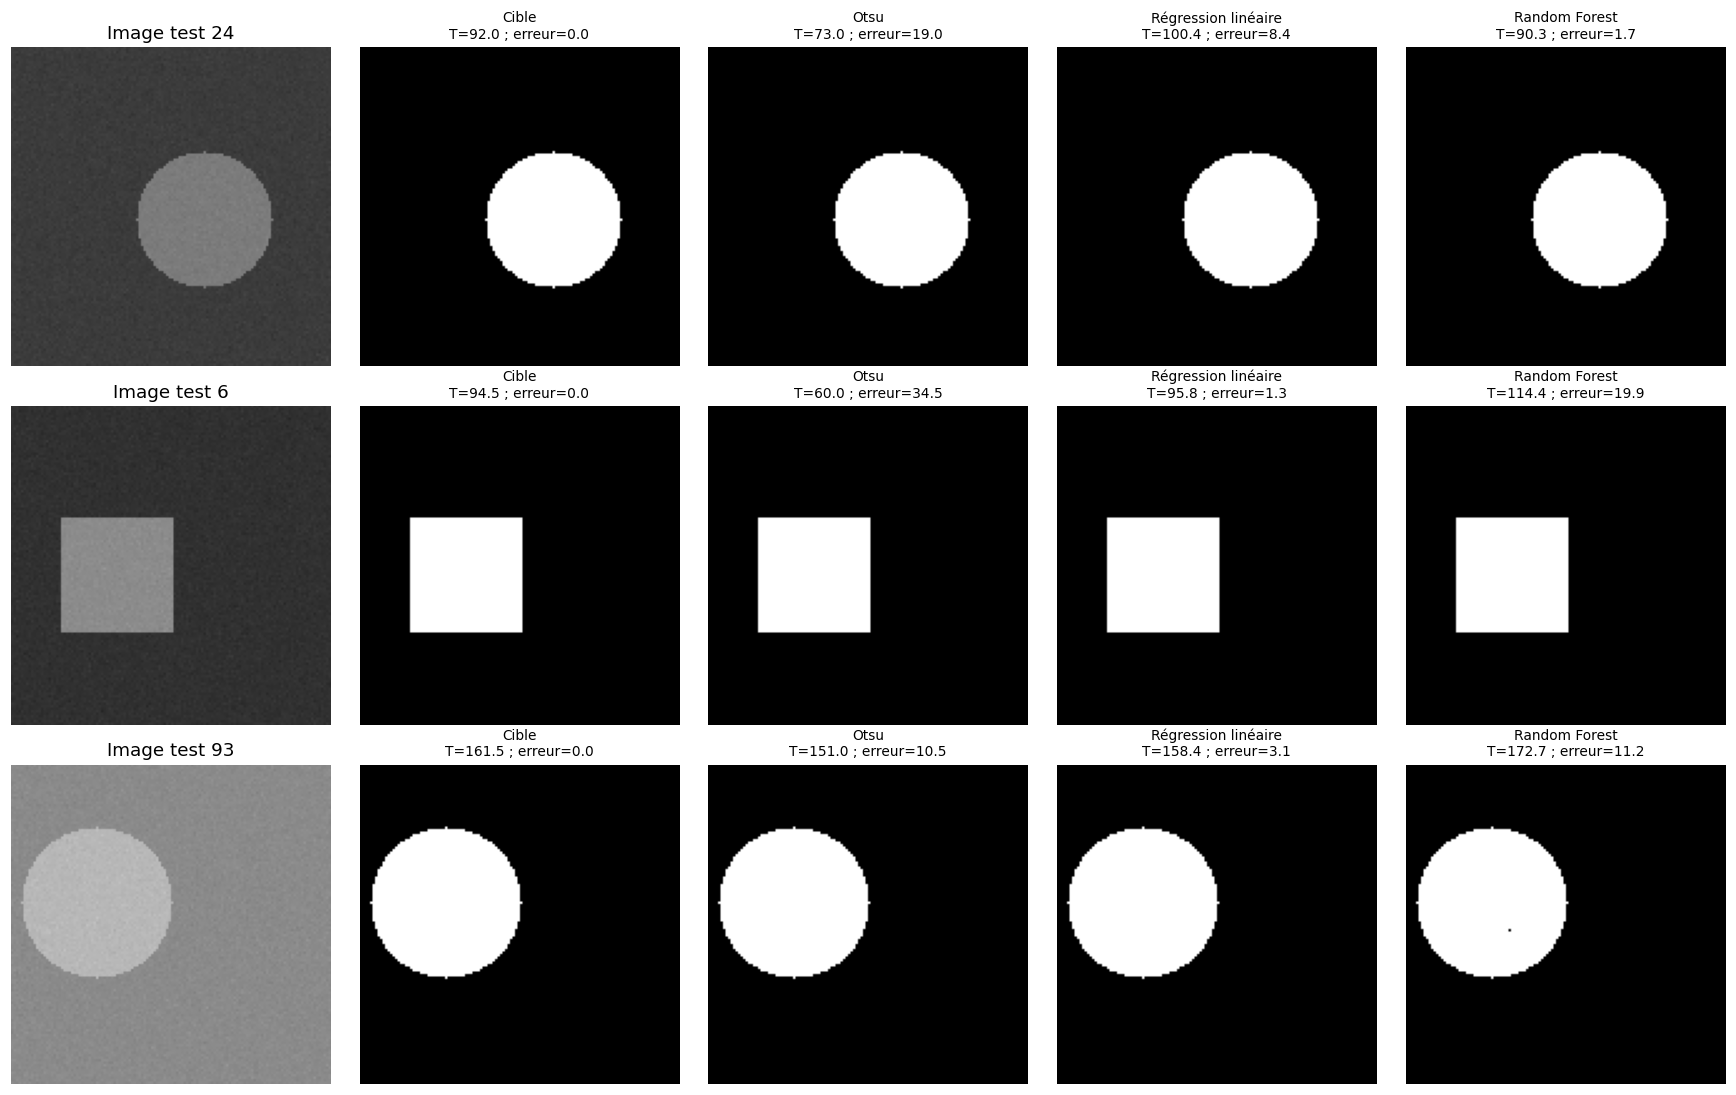

**Commentaire de la visualisation 24 :** Otsu : 0.00 % de pixels différents; Régression linéaire : 0.00 % de pixels différents; Random Forest : 0.00 % de pixels différents.

**Commentaire de la visualisation 6 :** Otsu : 0.00 % de pixels différents; Régression linéaire : 0.00 % de pixels différents; Random Forest : 0.00 % de pixels différents.

**Commentaire de la visualisation 93 :** Otsu : 0.00 % de pixels différents; Régression linéaire : 0.00 % de pixels différents; Random Forest : 0.01 % de pixels différents.

,erreur_absolue,IoU_objet,exactitude_pixels
méthode,,,
Cible,0.0000,1.0000,1.0000
Otsu,40.7667,1.0000,1.0000
Random Forest,9.1332,0.9915,0.9990
Régression linéaire,15.0752,0.9424,0.9844


In [5]:
def comparison(images, frame, test_idx, predictions, label, masks=None):
    rows = []
    for pos, idx in enumerate(test_idx):
        target = float(frame.iloc[idx]['cible'])
        thresholds = {'Cible':target, **{name:float(pred[pos]) for name,pred in predictions.items()}}
        for name, raw in thresholds.items():
            threshold = float(np.clip(raw,0,255))
            mask = images[idx] > threshold
            target_mask = images[idx] > target
            changed = float(np.mean(mask != target_mask))
            row = {'image_index':int(idx),'méthode':name,'seuil_brut':raw,
                   'seuil_appliqué':threshold,'cible':target,'erreur_absolue':abs(raw-target),
                   'pixels_différents_cible_pct':100*changed}
            if 'fichier' in frame.columns:
                row['fichier'] = frame.iloc[idx]['fichier']
            if masks is not None:
                truth = masks[idx]
                union = np.logical_or(mask,truth).sum()
                row['IoU_objet'] = np.logical_and(mask,truth).sum()/union if union else 1.0
                row['exactitude_pixels'] = np.mean(mask==truth)
            row['commentaire'] = ('Masque identique à celui de la cible' if changed==0 else
                                  f'{100*changed:.2f} % des pixels changent par rapport au masque cible')
            rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(OUT / f'{label}_comparaison.csv',index=False)
    chosen = list(test_idx[:3])
    display(table[table.image_index.isin(chosen)].round(4))
    fig, axes = plt.subplots(3, 5, figsize=(16, 10))
    for row, idx in enumerate(chosen):
        pos = list(test_idx).index(idx)
        thresholds = {'Cible':float(frame.iloc[idx]['cible']),
                      **{name:float(pred[pos]) for name,pred in predictions.items()}}
        axes[row,0].imshow(images[idx],cmap='gray',vmin=0,vmax=255)
        axes[row,0].set_title(f'Image test {idx}')
        for ax,(name,raw) in zip(axes[row,1:],thresholds.items()):
            ax.imshow(images[idx]>np.clip(raw,0,255),cmap='gray',vmin=0,vmax=1)
            ax.set_title(f'{name}\nT={raw:.1f} ; erreur={abs(raw-frame.iloc[idx]["cible"]):.1f}',fontsize=9)
        for ax in axes[row]: ax.axis('off')
    plt.tight_layout(); plt.show()
    for idx in chosen:
        subset = table[(table.image_index==idx)&(table['méthode']!='Cible')]
        detail = '; '.join(f'{r["méthode"]} : {r["pixels_différents_cible_pct"]:.2f} % de pixels différents' for _,r in subset.iterrows())
        display(Markdown(f'**Commentaire de la visualisation {idx} :** {detail}.'))
    if masks is not None:
        display(table.groupby('méthode')[['erreur_absolue','IoU_objet','exactitude_pixels']].mean().round(4))
    return table

comparison_syn = comparison(images_syn, df_syn, test_syn, pred_syn, 'synthetique', masks_syn)


### Réponses D

1. La régression linéaire peut extrapoler hors de [0,255]. Une forêt moyenne les cibles d’apprentissage, donc ses prédictions restent dans leur intervalle. Pour appliquer un seuil valide, nous utilisons `np.clip`; les métriques brutes restent disponibles pour ne pas masquer les extrapolations.
2. Une erreur de seuil importante peut ne modifier aucun pixel si l’histogramme présente un intervalle vide. Inversement, une petite erreur près d’un pic peut modifier beaucoup de pixels. La segmentation doit être évaluée par rapport à un masque annoté, par exemple avec IoU ou Dice.
3. Notre expérience synthétique impose deux classes séparées, un objet clair et un bruit limité. Les modèles peuvent apprendre ces particularités et échouer dans d’autres situations.
4. Il faudrait des masques de segmentation de référence, un objectif précis, une séparation par scène/source, une diversité d’éclairages et de textures, et une évaluation sur un test indépendant. Il faudrait aussi comparer à des méthodes adaptées, notamment le seuillage local.

## Application demandée — Images de `./dataset`

Le dossier contient des photographies et des annotations COCO de détection de personnes. Les boîtes englobantes ne fournissent ni masque pixel à pixel, ni seuil cible. Nous ne les transformons donc pas en vérité terrain de seuillage.

**Pseudo-cible réelle :** nous regroupons les intensités en deux classes par une méthode itérative déterministe à deux centres, puis prenons le milieu des deux centres. C’est une règle heuristique, pas un seuil idéal annoté. Elle est proche du principe de partition d’Otsu ; leur proximité éventuelle ne valide pas la segmentation des personnes.

Les variantes Roboflow d’un même fichier sont regroupées par nom avant `.rf.`. Une séparation **75 % / 25 % des groupes** avec `random_state=42` limite les fuites entre variantes. La proportion d’images peut légèrement différer. Les sous-dossiers d’origine sont conservés dans l’inventaire, mais réunis pour appliquer cette séparation. Le regroupement par nom ne garantit pas que deux noms différents ne montrent jamais une même scène.

In [6]:
candidates = [Path('dataset'), Path('.')]
DATA_DIR = next((p for p in candidates if (p/'train').is_dir() and (p/'valid').is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Dossier introuvable : lancer le notebook à côté de ./dataset ou adapter DATA_DIR.')
paths = sorted(p for p in DATA_DIR.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp'})
if len(paths)<4:
    raise ValueError('Au moins quatre images sont nécessaires.')

def pseudo_target(image):
    # Deux centres pondérés par l’histogramme, sans calculer Otsu.
    histogram = np.bincount(image.ravel(), minlength=256).astype(float)
    levels = np.arange(256,dtype=float)
    centers = np.percentile(image,[20,80]).astype(float)
    if centers[0] == centers[1]:
        centers = np.array([float(image.min()),float(image.max())])
    for _ in range(100):
        left = levels <= centers.mean()
        updated = centers.copy()
        for k, selection in enumerate((left,~left)):
            weight = histogram[selection].sum()
            if weight:
                updated[k] = np.dot(levels[selection],histogram[selection])/weight
        if np.max(np.abs(updated-centers))<1e-6:
            centers = updated
            break
        centers = updated
    return float(centers.mean())

images_real, records = [], []
for path in paths:
    image = cv2.imread(str(path),cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f'Image illisible : {path}')
    # Limiter le coût du calcul et des figures ; ratio conservé.
    scale = min(1.0,384/max(image.shape))
    if scale<1:
        image = cv2.resize(image,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA)
    images_real.append(image)
    record = dict(zip(FEATURES,features(image)))
    record.update(fichier=str(path), source=path.parent.name,
                  groupe=path.stem.split('.rf.')[0],
                  otsu=otsu_threshold(image)[0],cible=pseudo_target(image))
    records.append(record)
df_real = pd.DataFrame(records)
if df_real['groupe'].nunique()<4:
    raise ValueError('Nombre insuffisant de groupes indépendants.')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.25,random_state=SEED)
train_real,test_real = next(splitter.split(df_real,groups=df_real['groupe']))
assert set(df_real.iloc[train_real].groupe).isdisjoint(set(df_real.iloc[test_real].groupe))
df_real['partition'] = 'apprentissage'
df_real.loc[test_real,'partition'] = 'test'
df_real.to_csv(OUT/'images_reelles_inventaire.csv',index=False)
print(f'{len(df_real)} photographies, {df_real.groupe.nunique()} groupes distincts')
print(f'Apprentissage : {len(train_real)} images ; test : {len(test_real)} images')
display(pd.crosstab(df_real.source,df_real.partition))
display(df_real.head())


123 photographies, 51 groupes distincts
Apprentissage : 92 images ; test : 31 images


partition,apprentissage,test
source,,
train,81,27
valid,11,4


,moyenne,ecart_type,proportion_le_127,fichier,source,groupe,otsu,cible,partition
0,99.427789,90.034596,0.659254,dataset/train/1_jpeg.rf.6b132bcca952ede9c02051...,train,1_jpeg,124.0,123.969168,apprentissage
1,117.127455,66.568618,0.561869,dataset/train/1_jpeg.rf.84d41afcee257509e4961c...,train,1_jpeg,121.0,121.653217,apprentissage
2,86.308004,48.871495,0.766290,dataset/train/1_jpeg.rf.c4e734947d5ddd12507f81...,train,1_jpeg,85.0,84.983578,apprentissage
3,109.853461,73.221692,0.623216,dataset/train/2_jpeg.rf.199ad8976ae1e8461a6b32...,train,2_jpeg,123.0,123.647849,apprentissage
4,31.082228,48.144384,0.939704,dataset/train/2_jpeg.rf.ce6554a4f6c08b6b341e27...,train,2_jpeg,83.0,83.601193,apprentissage


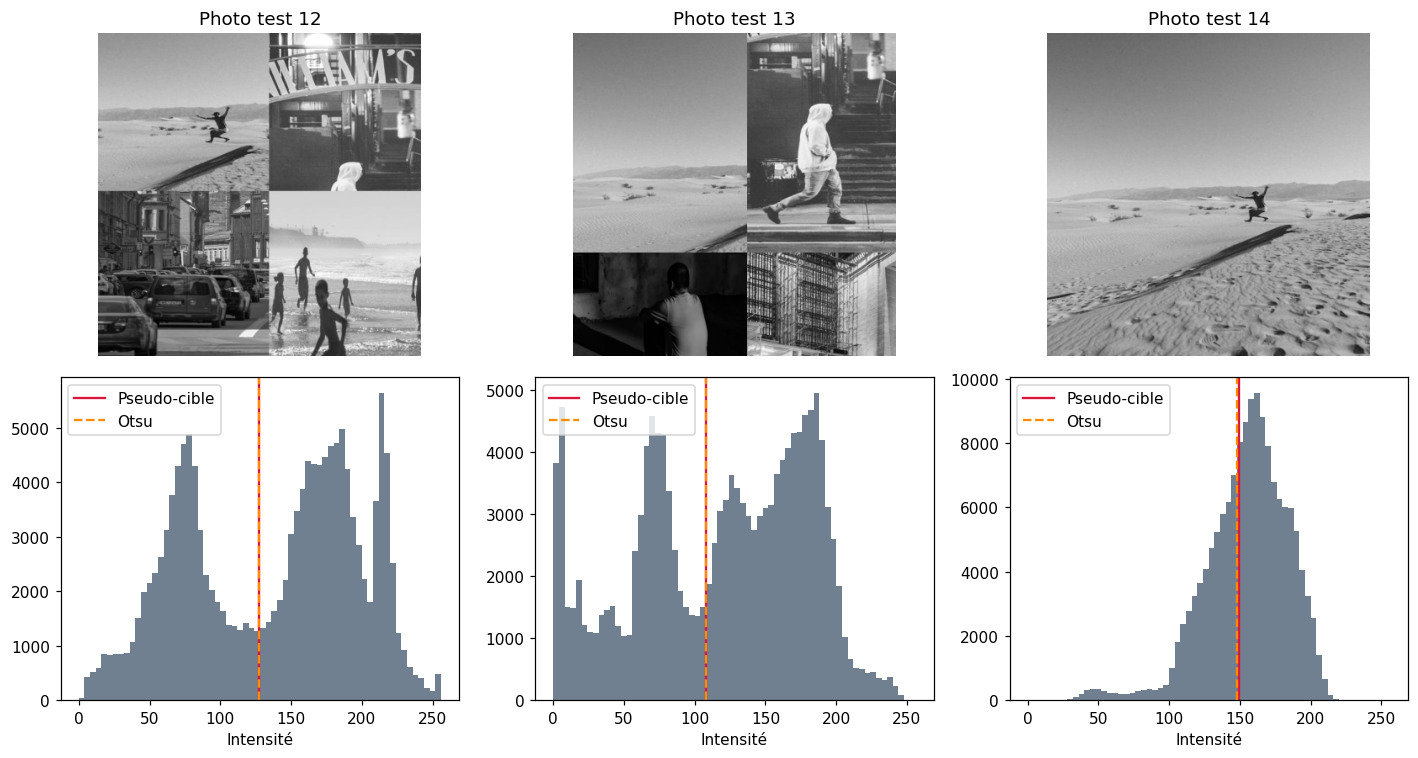

,MAE,RMSE,R2,"hors_[0,255]"
méthode,,,,
Otsu,0.5085,0.5895,0.9992,0
Régression linéaire,7.9828,9.8671,0.7898,0
Random Forest,7.7696,9.7881,0.7932,0


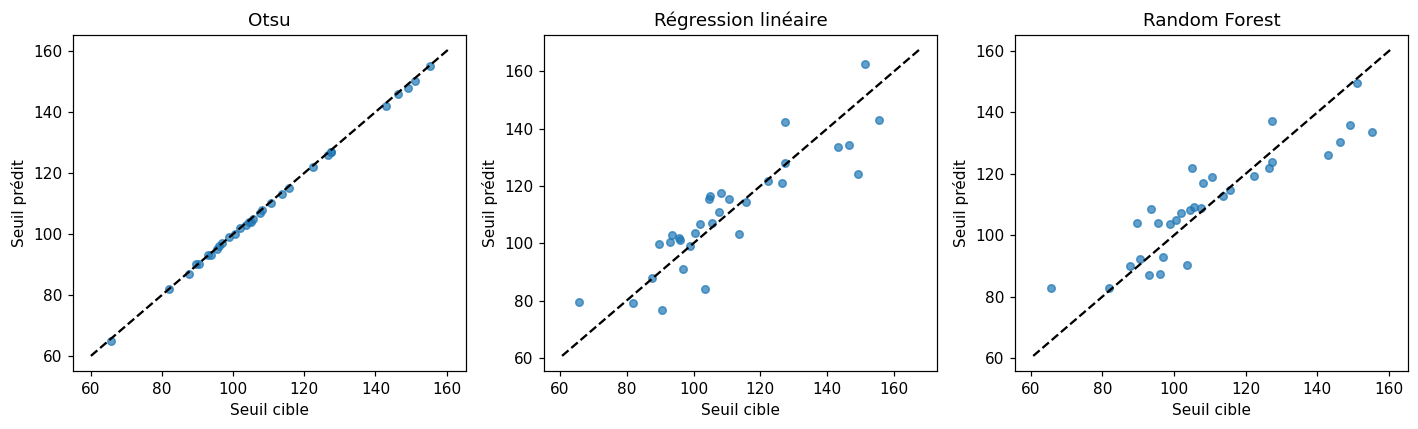

,image_index,méthode,seuil_brut,seuil_appliqué,cible,erreur_absolue,pixels_différents_cible_pct,fichier,commentaire
0,12,Cible,127.4649,127.4649,127.4649,0.0000,0.0000,dataset/train/8_jpeg.rf.14a0b87d22bd3bd34514c9...,Masque identique à celui de la cible
1,12,Otsu,127.0000,127.0000,127.4649,0.4649,0.0000,dataset/train/8_jpeg.rf.14a0b87d22bd3bd34514c9...,Masque identique à celui de la cible
2,12,Régression linéaire,127.8647,127.8647,127.4649,0.3998,0.0000,dataset/train/8_jpeg.rf.14a0b87d22bd3bd34514c9...,Masque identique à celui de la cible
3,12,Random Forest,123.9536,123.9536,127.4649,3.5114,0.8572,dataset/train/8_jpeg.rf.14a0b87d22bd3bd34514c9...,0.86 % des pixels changent par rapport au masq...
4,13,Cible,108.1732,108.1732,108.1732,0.0000,0.0000,dataset/train/8_jpeg.rf.20b739cc6f87a324309565...,Masque identique à celui de la cible
5,13,Otsu,108.0000,108.0000,108.1732,0.1732,0.0000,dataset/train/8_jpeg.rf.20b739cc6f87a324309565...,Masque identique à celui de la cible
6,13,Régression linéaire,117.6737,117.6737,108.1732,9.5004,3.7543,dataset/train/8_jpeg.rf.20b739cc6f87a324309565...,3.75 % des pixels changent par rapport au masq...
7,13,Random Forest,117.0763,117.0763,108.1732,8.9030,3.7543,dataset/train/8_jpeg.rf.20b739cc6f87a324309565...,3.75 % des pixels changent par rapport au masq...
8,14,Cible,149.0741,149.0741,149.0741,0.0000,0.0000,dataset/train/8_jpeg.rf.f310fc650df53f425a5ef8...,Masque identique à celui de la cible
9,14,Otsu,148.0000,148.0000,149.0741,1.0741,1.3502,dataset/train/8_jpeg.rf.f310fc650df53f425a5ef8...,1.35 % des pixels changent par rapport au masq...


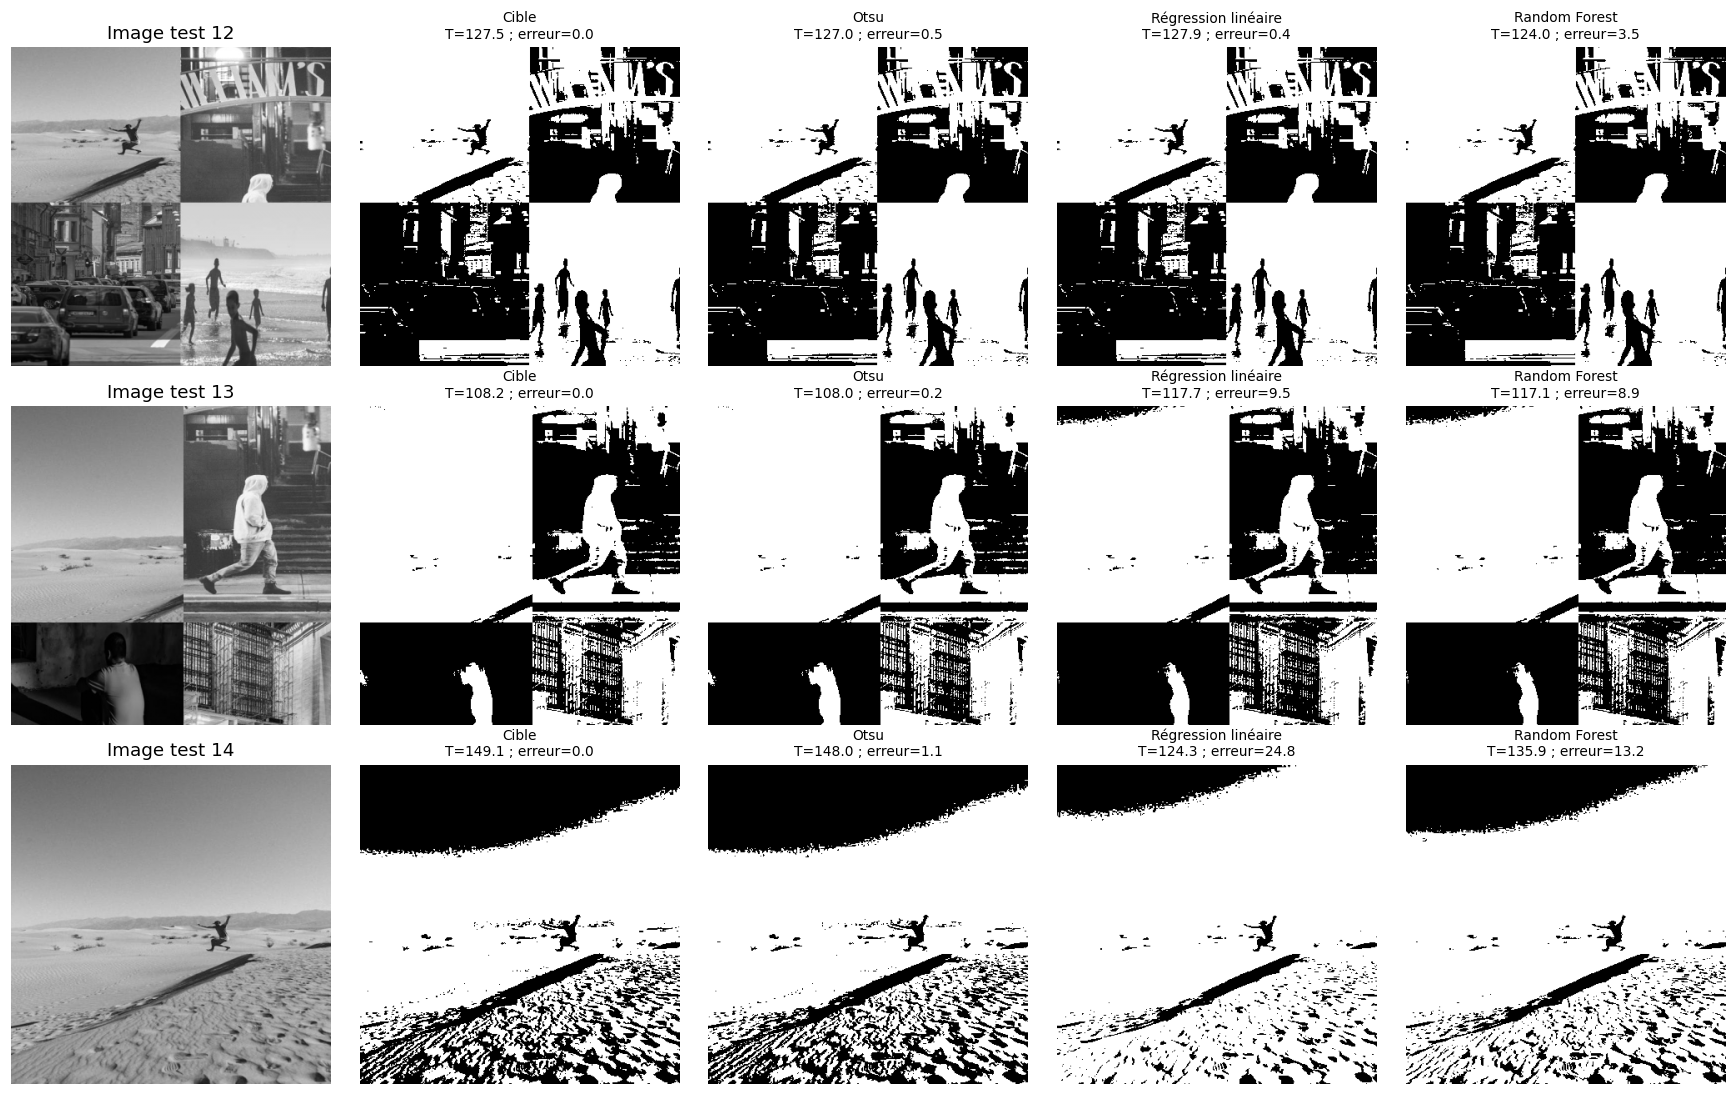

**Commentaire de la visualisation 12 :** Otsu : 0.00 % de pixels différents; Régression linéaire : 0.00 % de pixels différents; Random Forest : 0.86 % de pixels différents.

**Commentaire de la visualisation 13 :** Otsu : 0.00 % de pixels différents; Régression linéaire : 3.75 % de pixels différents; Random Forest : 3.75 % de pixels différents.

**Commentaire de la visualisation 14 :** Otsu : 1.35 % de pixels différents; Régression linéaire : 24.38 % de pixels différents; Random Forest : 15.51 % de pixels différents.

Parmi les modèles supervisés, **Random Forest** imite le mieux la pseudo-cible sur ce test (MAE = 7.770). Il ne s’agit pas d’une mesure de segmentation des personnes.

In [7]:
fig, axes = plt.subplots(2,3,figsize=(13,7))
for col,idx in enumerate(test_real[:3]):
    im = images_real[idx]
    axes[0,col].imshow(im,cmap='gray',vmin=0,vmax=255)
    axes[0,col].set_title(f'Photo test {idx}'); axes[0,col].axis('off')
    axes[1,col].hist(im.ravel(),bins=64,range=(0,256),color='slategray')
    axes[1,col].axvline(df_real.loc[idx,'cible'],color='crimson',label='Pseudo-cible')
    axes[1,col].axvline(df_real.loc[idx,'otsu'],color='darkorange',linestyle='--',label='Otsu')
    axes[1,col].set_xlabel('Intensité'); axes[1,col].legend()
plt.tight_layout(); plt.show()
models_real,pred_real,metrics_real = train_evaluate(df_real,train_real,test_real,'reel')
comparison_real = comparison(images_real,df_real,test_real,pred_real,'reel')
best_real = metrics_real.loc[['Régression linéaire','Random Forest'],'MAE'].idxmin()
display(Markdown(f'Parmi les modèles supervisés, **{best_real}** imite le mieux la pseudo-cible sur ce test (MAE = {metrics_real.loc[best_real,"MAE"]:.3f}). Il ne s’agit pas d’une mesure de segmentation des personnes.'))


## Conclusion

L’expérience synthétique évalue l’apprentissage d’un seuil défini à partir d’intensités connues. Otsu calcule directement une séparation statistique ; la régression et la forêt apprennent une relation entre des caractéristiques et une cible. L’erreur sur le seuil et la qualité du masque mesurent deux aspects différents.

L’application aux photographies locales montre comment adapter cette chaîne à des images réelles et comparer les résultats visuellement. Comme les seuils réels sont des pseudo-cibles et que les annotations disponibles sont des boîtes de détection, les scores ne permettent pas d’affirmer qu’un modèle segmente mieux les personnes ou surpasse Otsu. Cette affirmation nécessiterait des masques annotés et un test indépendant.

Les tableaux exportés contiennent les performances, les seuils et erreurs de chaque image de test, ainsi que l’inventaire des images réelles et leurs partitions.


In [8]:
df_syn.assign(partition=np.where(np.isin(np.arange(len(df_syn)),test_syn),'test','apprentissage')).to_csv(OUT/'synthetique_inventaire.csv',index=False)
print('Tableaux enregistrés :')
for p in sorted(OUT.glob('*.csv')):
    print(' -',p)
# Vérifications de cohérence de l’expérience
assert len(images_syn)>=100
assert len(test_syn)==60
assert all(im.dtype==np.uint8 for im in images_syn+images_real)
assert all(np.isfinite(pred).all() for pred in [*pred_syn.values(),*pred_real.values()])
print('Vérifications terminées.')


Tableaux enregistrés :
 - resultats_seuillage/images_reelles_inventaire.csv
 - resultats_seuillage/reel_comparaison.csv
 - resultats_seuillage/reel_performances.csv
 - resultats_seuillage/synthetique_comparaison.csv
 - resultats_seuillage/synthetique_inventaire.csv
 - resultats_seuillage/synthetique_performances.csv
Vérifications terminées.


## Questions théoriques complémentaires — réponses

Ces questions de révision explicitent les notions utilisées dans le TP ; elles complètent les consignes pratiques de l’énoncé.

### 1. Qu’est-ce que le filtrage d’une image ?
Le filtrage transforme les pixels à partir de leur voisinage pour atténuer le bruit, lisser l’image ou mettre en évidence les détails. Un filtre linéaire utilise une combinaison pondérée des voisins ; le médian est non linéaire.

### 2. Quelle différence entre image couleur et image en niveaux de gris ?
Une image grise possède une intensité par pixel. Une image RGB possède trois composantes, rouge, verte et bleue. Les filtres de lissage peuvent traiter les deux types, mais la balance des blancs nécessite plusieurs canaux. Nous utilisons donc `images_color.jpeg`.

### 3. Pourquoi convertir BGR en RGB ?
OpenCV charge les canaux dans l’ordre BGR, tandis que Matplotlib attend RGB. La conversion évite d’inverser le rouge et le bleu à l’affichage ; elle ne constitue pas une correction de couleur.

### 4. À quoi sert l’histogramme ?
Il décrit la fréquence des intensités. Une concentration vers les faibles valeurs suggère une image sombre ; une forte accumulation aux extrêmes peut signaler de l’écrêtage. Il faut aussi observer l’image, car une scène naturellement sombre peut être correctement exposée. Deux images différentes peuvent avoir le même histogramme.

### 5. Qu’est-ce qu’un bruit gaussien et un bruit sel et poivre ?
Le bruit gaussien est ici une perturbation additive tirée d’une loi normale de moyenne nulle. Le bruit sel et poivre remplace aléatoirement certains pixels par du noir ou du blanc. Ils modélisent deux défauts différents et ne représentent pas tous les bruits réels d’un appareil photo.

### 6. Comment fonctionne le filtre gaussien ?
Il calcule une moyenne locale pondérée par une gaussienne. Les voisins proches ont davantage de poids. C’est un filtre passe-bas : il atténue les hautes fréquences, y compris une partie des détails. Un σ ou un noyau plus grand augmente généralement le lissage et le risque de flou.

### 7. Pourquoi le filtre médian est-il adapté au bruit impulsionnel ?
La médiane dépend du rang des valeurs plutôt que de leur amplitude. Une valeur isolée égale à 0 ou 255 influence donc moins le résultat qu’une moyenne. Si trop de pixels du voisinage sont corrompus, le filtre peut toutefois échouer ; il peut aussi supprimer de petites structures.

### 8. Quel est le compromis entre réduction du bruit et conservation des détails ?
Le bruit et les contours contiennent tous deux des variations rapides. Les atténuer sans distinction réduit aussi les textures utiles. Il faut choisir un noyau et une intensité de traitement adaptés, puis vérifier des régions avec contours et textures.

### 9. Que corrige la balance des blancs ? Quelle est la limite du monde gris ?
Elle ajuste les gains des canaux pour compenser une dominante liée à l’éclairage. Le monde gris suppose que la couleur moyenne de la scène devrait être neutre. Une scène naturellement très verte ou rouge peut violer cette hypothèse : sa correction automatique peut dénaturer les couleurs.

### 10. Quel est l’effet du paramètre gamma ?
Avec la convention de ce notebook,

$$I_{sortie}=255\left(\frac{I_{entrée}}{255}\right)^\gamma,$$

γ < 1 éclaircit les tons intermédiaires, γ > 1 les assombrit et γ = 1 conserve les valeurs. Le gamma modifie le rendu tonal ; il ne remplace pas une balance des blancs et ne restaure pas les zones saturées.

### 11. Qu’est-ce que le Laplacien et pourquoi travailler en flottants ?
Le Laplacien est une somme de dérivées secondes : il répond aux variations rapides de l’image. Avec l’opérateur utilisé ici, on accentue par $I-\alpha\Delta I$. Les dérivées pouvant être négatives, un type flottant évite leur perte pendant le calcul. On borne ensuite le résultat dans [0,255] avant conversion en `uint8`.

### 12. Pourquoi débruiter avant d’accentuer et travailler sur la luminance ?
L’accentuation renforcerait aussi le bruit si on l’appliquait directement. Un débruitage préalable limite cet effet. Modifier seulement la luminance LAB réduit les changements de teinte, même si les conversions et l’écrêtage peuvent encore modifier légèrement les couleurs.

### 13. Comment évaluer la qualité ?
Visuellement, on examine le bruit résiduel, les contours, les textures, les couleurs et les halos à la même échelle. Avec une référence, on peut calculer :

$$\mathrm{MSE}=\frac{1}{N}\sum_{i=1}^{N}(I_i-R_i)^2,\qquad
\mathrm{PSNR}=10\log_{10}\left(\frac{255^2}{\mathrm{MSE}}\right).$$

Ici, $N$ inclut les pixels et les trois canaux. Une MSE plus faible et une PSNR plus élevée indiquent une meilleure fidélité à la référence. Si la MSE est nulle, la PSNR est infinie. Ces indicateurs ne résument pas toute la qualité perceptuelle.

### 14. Une variance du Laplacien élevée prouve-t-elle une image de meilleure qualité ?
Non. Elle peut refléter des contours nets, mais aussi du bruit ou des halos. Elle dépend du contenu de la scène ; il faut l’interpréter avec les images et les autres mesures.

### 15. Peut-on mesurer exactement l’amélioration d’une photo sans référence ?
On peut décrire son rendu et utiliser des indicateurs indirects, mais on ne peut pas calculer une erreur par rapport à une image parfaite inconnue. C’est pourquoi les mesures de fidélité du TP utilisent des dégradations artificielles connues. La photographie initiale n’est pas supposée parfaite.

### 16. Faut-il toujours appliquer toute la chaîne ?
Non. Chaque opération doit répondre à un défaut observé. Une image déjà nette et peu bruitée peut être dégradée par un lissage ou une accentuation inutiles. Les réglages de ce notebook illustrent les méthodes ; leur généralisation demanderait plusieurs images et une validation adaptée.
